# Hepsiburada Yorumlarıyla Türkçe Duygu Analizi (Olumsuz / Nötr / Olumlu)

**Bu sürümde orijinal notebook'a göre yapılan başlıca iyileştirmeler**

| # | Orijinaldeki sorun | Bu sürümdeki çözüm |
|---|---|---|
| 1 | LSTM hücresi tanımsız `max_uzunluk` / `max_kelime_sayisi` değişkenlerini kullanıyor (tokenizer hücresi yok → `NameError`), model hiç eğitilmiyor | Çalışmayan LSTM kaldırıldı; yerine hızlı bir **TF-IDF baseline** ve asıl model olarak **BERTurk** kondu |
| 2 | `str.lower()` Türkçede `I→i`, `İ→i̇` yapıyor (hatalı) | Türkçe'ye duyarlı `tr_lower` |
| 3 | Regex noktalama, `!`, `?`, emoji gibi duygu taşıyan işaretleri siliyor | Transformer'a ham metin (hafif normalizasyon) verilir; baseline'da işaretler korunur |
| 4 | Aynı yorum birden çok kez geçebilir → train/test **sızıntısı** (gerçekte olduğundan yüksek skor) | Normalize edilmiş metne göre **tekilleştirme**; çelişkili etiketli kopyalar atılır |
| 5 | Undersampling ile 272K yorumun ~%85'i çöpe gidiyor; test seti yapay dengeli | Önce **doğal dağılımla** train/val/test bölünür; yalnızca eğitimde ılımlı alt-örnekleme + **sınıf ağırlıklı kayıp**. Test doğal ve dengeli iki şekilde raporlanır |
| 6 | Etiket gürültüsü (ör. 5 yıldız ama şikayet metni) | Yalnızca **train** kümesinde cross-validation ile güvenle çelişen örnekler ayıklanır |
| 7 | Sınıf sırası alfabetik (Nötr=0) → anlamsız | Sıralı etiketler: Olumsuz=0, Nötr=1, Olumlu=2 |
| 8 | Eşik/önyargı ayarı yok | Validation üzerinde **logit bias ayarı** + BERT ⊕ TF-IDF **harmanlama** (macro-F1'e göre) |
| 9 | Hata analizi yok | Karışıklık matrisi, sınıf bazlı rapor, en emin yanlış tahminler |

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [1]:
!pip install --upgrade transformers

In [2]:
!pip install -q -U transformers datasets accelerate scikit-learn

In [3]:
import os
os.environ["USE_TF"] = "0"          # transformers TensorFlow yerine PyTorch kullansın
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import re, json, random, inspect, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.special import softmax, log_softmax

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="pastel")

# ------------------------------------------------------------------
# AYARLAR
# ------------------------------------------------------------------
SEED = 42
DOSYA_ADI = "hb.csv"

SINIFLAR = ["Olumsuz", "Nötr", "Olumlu"]            # 0, 1, 2 (sıralı)
SINIF_ID = {s: i for i, s in enumerate(SINIFLAR)}

CAP_RATIO        = 5      # train'de en büyük sınıf, en küçük sınıfın en fazla 5 katı olsun
GURULTU_ESIK     = 0.05   # CV'de gerçek etiket olasılığı bu değerin altındaysa şüpheli
GURULTU_MAX_ORAN = 0.08   # her sınıftan en fazla %8'i ayıkla
GURULTU_TEMIZLE  = True

MODEL_ADI    = "dbmdz/bert-base-turkish-128k-cased"   # alternatif: "dbmdz/bert-base-turkish-cased"
MAX_LEN      = 128
BATCH        = 32
LR           = 3e-5
EPOCH        = 4
LABEL_SMOOTH = 0.05

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass
seed_everything()

## 1. Veriyi yükleme ve keşif

In [4]:
if not os.path.exists(DOSYA_ADI):
    try:                                   # Colab'da dosya yoksa yükleme penceresi aç
        from google.colab import files
        print(f"'{DOSYA_ADI}' bulunamadı, lütfen yükleyin...")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"'{DOSYA_ADI}' bulunamadı.")

df_ham = pd.read_csv(DOSYA_ADI)
df_ham = df_ham.rename(columns={"Rating (Star)": "rating", "Review": "review"})
print("Ham boyut:", df_ham.shape)
print(df_ham.dtypes, "\n")
print("Eksik değerler:\n", df_ham.isna().sum(), "\n")
display(df_ham.head())

Ham boyut: (272216, 3)
rating     int64
review    object
URL       object
dtype: object 

Eksik değerler:
 rating    0
review    0
URL       0
dtype: int64 



,rating,review,URL
0,5,3 yıldır tık demedi. :),https://www.hepsiburada.com/logitech-m175-kabl...
1,5,3 yıldır kullanıyorum müthiş,https://www.hepsiburada.com/logitech-m175-kabl...
2,4,Ürün bugün elime geçti çok fazla inceleme fırs...,https://www.hepsiburada.com/logitech-m175-kabl...
3,4,Almaya karar verdim. Hemencecik geldi. Keyifle...,https://www.hepsiburada.com/logitech-m175-kabl...
4,5,Günlük kullanımınızı çok çok iyi karsılıyor kı...,https://www.hepsiburada.com/logitech-m175-kabl...


## 2. Temizlik, etiketleme, tekilleştirme

* Türkçe'ye duyarlı küçük harfe çevirme (yalnızca eşleştirme anahtarı ve TF-IDF için).
* **Tekilleştirme:** aynı yorumun hem train hem test'te bulunması skoru şişirir. Normalize metne göre tekilleştirilir, farklı etiketli kopyalar tamamen atılır (etiket belirsiz).
* Etiket: 1-2 ⭐ → Olumsuz, 3 ⭐ → Nötr, 4-5 ⭐ → Olumlu.

Ham: 272,216 → boş/geçersiz sonrası: 272,216 → tekil ve tutarlı: 235,179
Çelişkili etiketli tekil metin sayısı (atıldı): 309


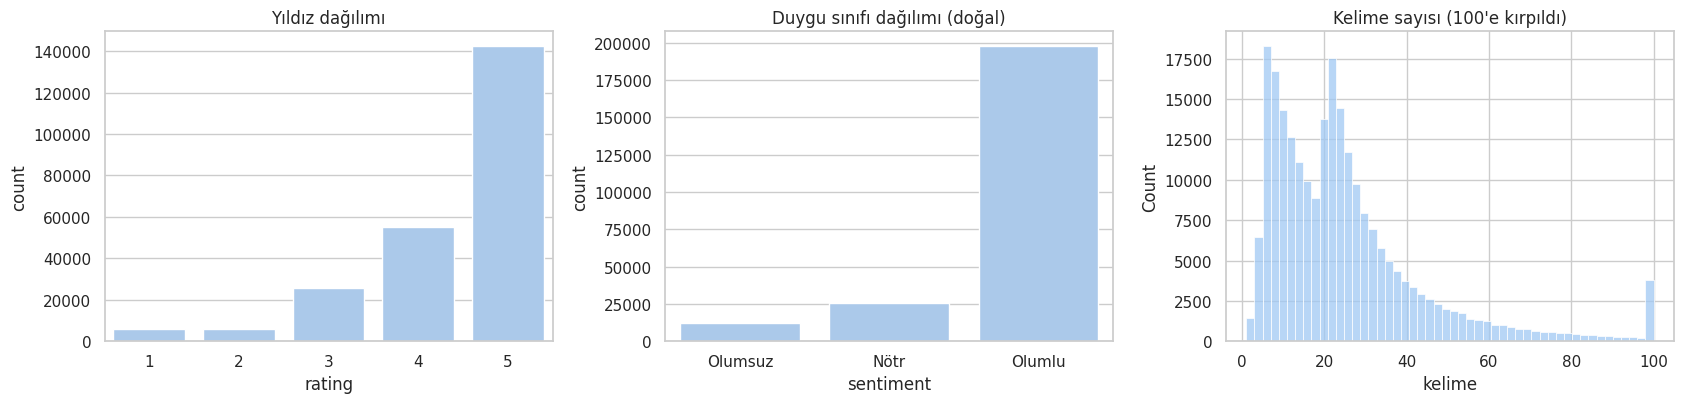

sentiment
Olumsuz     11910
Nötr        25463
Olumlu     197806
Name: count, dtype: int64

Kelime sayısı: ortalama 25.4, medyan 21, %95 = 64


In [5]:
def tr_lower(s: str) -> str:
    """Türkçe'ye uygun küçük harf: I->ı, İ->i (Python'un varsayılanı bunu yanlış yapar)."""
    s = s.replace("I", "ı").replace("İ", "i").lower()
    return s.replace("̇", "")          # artık birleşik nokta işaretini at

_url   = re.compile(r"https?://\S+|www\.\S+")
_space = re.compile(r"\s+")
_rep   = re.compile(r"(.)\1{2,}")           # 'çoooook' -> 'çook'

def hafif_norm(s) -> str:
    """Ham metni (büyük/küçük harf, noktalama, emoji korunarak) hafifçe temizler."""
    s = str(s)
    s = _url.sub(" ", s)
    s = _rep.sub(r"\1\1", s)
    return _space.sub(" ", s).strip()

def anahtar(s: str) -> str:
    """Tekilleştirme için agresif normalize anahtar."""
    return re.sub(r"[^0-9a-zçğıöşü]+", "", tr_lower(s))

def puan_cevir(p):
    return "Olumsuz" if p <= 2 else ("Nötr" if p == 3 else "Olumlu")

df = df_ham.drop(columns=[c for c in ["URL"] if c in df_ham.columns]).copy()
n0 = len(df)

df = df.dropna(subset=["review", "rating"])
df["rating"] = df["rating"].astype(int)
df = df[df["rating"].between(1, 5)]
df["review"] = df["review"].map(hafif_norm)
df = df[df["review"].str.len() >= 2]
n1 = len(df)

df["sentiment"] = df["rating"].map(puan_cevir)
df["label"] = df["sentiment"].map(SINIF_ID)
df["key"] = df["review"].map(anahtar)
df = df[df["key"].str.len() > 0]

# Çelişkili kopyaları (aynı metin, farklı duygu) at; kalan kopyalardan ilkini tut
cakisma = df.groupby("key")["label"].nunique()
cakisan_keys = set(cakisma[cakisma > 1].index)
df = df[~df["key"].isin(cakisan_keys)]
df = df.drop_duplicates("key").reset_index(drop=True)

print(f"Ham: {n0:,} → boş/geçersiz sonrası: {n1:,} → tekil ve tutarlı: {len(df):,}")
print(f"Çelişkili etiketli tekil metin sayısı (atıldı): {len(cakisan_keys):,}")
df["kelime"] = df["review"].str.split().str.len()

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
sns.countplot(data=df, x="rating", ax=ax[0]); ax[0].set_title("Yıldız dağılımı")
sns.countplot(data=df, x="sentiment", order=SINIFLAR, ax=ax[1]); ax[1].set_title("Duygu sınıfı dağılımı (doğal)")
sns.histplot(df["kelime"].clip(upper=100), bins=50, ax=ax[2]); ax[2].set_title("Kelime sayısı (100'e kırpıldı)")
plt.tight_layout(); plt.show()

print(df["sentiment"].value_counts().reindex(SINIFLAR))
print(f"\nKelime sayısı: ortalama {df['kelime'].mean():.1f}, medyan {df['kelime'].median():.0f}, "
      f"%95 = {df['kelime'].quantile(.95):.0f}")

## 3. Train / Validation / Test bölme

Önce **doğal dağılımı bozmadan** katmanlı %80 / %10 / %10 bölünür. Validation ve test gerçek dünyayı temsil eder; dengeleme **yalnızca eğitim kümesine** uygulanır.

In [6]:
from sklearn.model_selection import train_test_split

y_all = df["label"].values
idx = np.arange(len(df))
tr_idx, tmp_idx = train_test_split(idx, test_size=0.20, stratify=y_all, random_state=SEED)
va_idx, te_idx  = train_test_split(tmp_idx, test_size=0.50, stratify=y_all[tmp_idx], random_state=SEED)

train_full = df.iloc[tr_idx].reset_index(drop=True)
val_df     = df.iloc[va_idx].reset_index(drop=True)
test_df    = df.iloc[te_idx].reset_index(drop=True)

# --- Yalnızca eğitimde ılımlı alt-örnekleme (en büyük sınıf <= CAP_RATIO x en küçük sınıf) ---
sayi = train_full["label"].value_counts()
cap = int(sayi.min() * CAP_RATIO)
parcalar = []
for c in range(len(SINIFLAR)):
    g = train_full[train_full["label"] == c]
    parcalar.append(g.sample(min(len(g), cap), random_state=SEED))
train_df = pd.concat(parcalar).sample(frac=1, random_state=SEED).reset_index(drop=True)

# Dengeli test (orijinal notebook ile kıyaslanabilir): her sınıftan eşit sayıda
m = test_df["label"].value_counts().min()
test_bal = pd.concat([test_df[test_df.label == c].sample(m, random_state=SEED)
                      for c in range(len(SINIFLAR))]).reset_index(drop=True)

def dagilim(d): return d["label"].map(dict(enumerate(SINIFLAR))).value_counts().reindex(SINIFLAR).to_dict()
print("Train (alt-örneklenmiş):", len(train_df), dagilim(train_df))
print("Validation (doğal)     :", len(val_df),   dagilim(val_df))
print("Test (doğal)           :", len(test_df),  dagilim(test_df))
print("Test (dengeli)         :", len(test_bal), dagilim(test_bal))

Train (alt-örneklenmiş): 77538 {'Olumsuz': 9528, 'Nötr': 20370, 'Olumlu': 47640}
Validation (doğal)     : 23518 {'Olumsuz': 1191, 'Nötr': 2546, 'Olumlu': 19781}
Test (doğal)           : 23518 {'Olumsuz': 1191, 'Nötr': 2547, 'Olumlu': 19780}
Test (dengeli)         : 3573 {'Olumsuz': 1191, 'Nötr': 1191, 'Olumlu': 1191}


## 4. Güçlü baseline: TF-IDF (kelime + karakter n-gram) + lineer model

Karakter n-gram'ları Türkçe'nin ek yapısına ve ASCII yazılmış yorumlara (`guzel`, `begenmedim`) karşı dayanıklıdır. Baseline iki işe yarar: (a) BERT'in gerçekten fark yarattığını ölçmek, (b) etiket gürültüsünü tespit etmek ve (c) sonda BERT ile harmanlanmak.

In [7]:
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

def fast_macro_f1(y, p, k=3):
    cm = np.bincount(y * k + p, minlength=k * k).reshape(k, k)
    tp = np.diag(cm).astype(float)
    prec = tp / np.maximum(cm.sum(0), 1)
    rec  = tp / np.maximum(cm.sum(1), 1)
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-12)
    return f1.mean()

tr_text = train_df["review"].map(tr_lower)
va_text = val_df["review"].map(tr_lower)
te_text = test_df["review"].map(tr_lower)
tb_text = test_bal["review"].map(tr_lower)

kelime_vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=250_000,
                             sublinear_tf=True, token_pattern=r"(?u)\b\w+\b|[!?]+")
karakter_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3,
                               max_features=300_000, sublinear_tf=True)

t0 = time.time()
Xtr = hstack([kelime_vec.fit_transform(tr_text), karakter_vec.fit_transform(tr_text)]).tocsr()
def vec(texts): return hstack([kelime_vec.transform(texts), karakter_vec.transform(texts)]).tocsr()
Xva, Xte, Xtb = vec(va_text), vec(te_text), vec(tb_text)
print(f"TF-IDF boyutu: {Xtr.shape}  ({time.time()-t0:.0f} sn)")

def yeni_lineer():
    return SGDClassifier(loss="log_loss", alpha=1e-5, class_weight="balanced",
                         max_iter=40, tol=1e-4, random_state=SEED, n_jobs=-1)

TF-IDF boyutu: (77538, 350593)  (122 sn)


### 4.1 Etiket gürültüsü ayıklama (yalnızca train)

Yıldız puanı ile metin her zaman uyuşmaz (ör. yanlışlıkla 5 yıldız verilmiş şikayet). Eğitim kümesinde 5-kat cross-validation ile tahmin yapılır; model, verilen etikete **çok düşük** olasılık veriyorsa örnek şüpheli sayılır ve atılır. Validation/test **asla** değiştirilmez, böylece değerlendirme dürüst kalır.

In [8]:
ytr = train_df["label"].values
keep = np.ones(len(train_df), dtype=bool)

if GURULTU_TEMIZLE:
    skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
    P = cross_val_predict(yeni_lineer(), Xtr, ytr, cv=skf, method="predict_proba")
    p_true = P[np.arange(len(ytr)), ytr]
    for c, ad in enumerate(SINIFLAR):
        ci = np.where(ytr == c)[0]
        sus = ci[p_true[ci] < GURULTU_ESIK]
        limit = int(len(ci) * GURULTU_MAX_ORAN)
        if len(sus) > limit:
            sus = sus[np.argsort(p_true[sus])[:limit]]
        keep[sus] = False
        print(f"{ad:8s}: {len(ci):6d} örnekten {len(sus):5d} şüpheli etiket ayıklandı")

    atilan = train_df[~keep][["review", "sentiment"]].head(8)
    print("\nAyıklanan örneklerden birkaçı (gözle kontrol):")
    display(atilan)

train_clean = train_df[keep].reset_index(drop=True)
print("\nTemiz train boyutu:", len(train_clean), dagilim(train_clean))

Olumsuz :   9528 örnekten   273 şüpheli etiket ayıklandı
Nötr    :  20370 örnekten   183 şüpheli etiket ayıklandı
Olumlu  :  47640 örnekten   138 şüpheli etiket ayıklandı

Ayıklanan örneklerden birkaçı (gözle kontrol):


,review,sentiment
2,Dan brown bence da Vinci&#8217;nin gölgesinde ...,Nötr
141,ürünün kargo süresi ve ulaşımı çok başarılı ka...,Olumsuz
347,ürün sipariş verdikten 1 gün sonra elimdeydi.s...,Nötr
371,güzel bir saz bu fiyata bu sazı dışarda bulama...,Olumsuz
433,ürün 2 gün sonra elime ulaştı.. kullanışlı,Olumsuz
453,Selam arkadaslar Fiyatına gore cok kalıtelı ve...,Olumsuz
456,Satıcı HepsiBurada olarak aldım 24 saat içinde...,Nötr
736,bir kac gün oldu elime ulaştı gercekten faydas...,Olumsuz



Temiz train boyutu: 76944 {'Olumsuz': 9255, 'Nötr': 20187, 'Olumlu': 47502}


In [9]:
# Baseline'ı temiz train üzerinde eğit ve değerlendir
lin = yeni_lineer().fit(Xtr[keep], ytr[keep])
P_lin_va, P_lin_te, P_lin_tb = (lin.predict_proba(X) for X in (Xva, Xte, Xtb))

def rapor(y, P, ad):
    p = P.argmax(1)
    print(f"\n===== {ad} =====")
    print(classification_report(y, p, target_names=SINIFLAR, digits=4))
    print(f"Accuracy: {accuracy_score(y, p):.4f} | Macro-F1: {f1_score(y, p, average='macro'):.4f}")

rapor(val_df.label.values, P_lin_va, "TF-IDF baseline — VALIDATION (doğal)")
rapor(test_df.label.values, P_lin_te, "TF-IDF baseline — TEST (doğal)")
rapor(test_bal.label.values, P_lin_tb, "TF-IDF baseline — TEST (dengeli)")


===== TF-IDF baseline — VALIDATION (doğal) =====
              precision    recall  f1-score   support

     Olumsuz     0.4716    0.6625    0.5510      1191
        Nötr     0.2572    0.3932    0.3110      2546
      Olumlu     0.9293    0.8434    0.8842     19781

    accuracy                         0.7855     23518
   macro avg     0.5527    0.6330    0.5821     23518
weighted avg     0.8333    0.7855    0.8053     23518

Accuracy: 0.7855 | Macro-F1: 0.5821

===== TF-IDF baseline — TEST (doğal) =====
              precision    recall  f1-score   support

     Olumsuz     0.4517    0.6364    0.5284      1191
        Nötr     0.2603    0.3950    0.3138      2547
      Olumlu     0.9287    0.8439    0.8843     19780

    accuracy                         0.7848     23518
   macro avg     0.5469    0.6251    0.5755     23518
weighted avg     0.8321    0.7848    0.8045     23518

Accuracy: 0.7848 | Macro-F1: 0.5755

===== TF-IDF baseline — TEST (dengeli) =====
              precision   

## 5. Asıl model: BERTurk ince ayarı (fine-tuning)

* Girdi: **ham (hafif normalize)** metin — BERT'in kendi tokenizer'ı büyük/küçük harf ve noktalamayı kullanır; agresif temizlik bilgi kaybettirir.
* **Sınıf ağırlıklı** çapraz-entropi + hafif label smoothing.
* Dinamik padding + `group_by_length` ile hızlı eğitim, fp16.
* Model seçimi **validation macro-F1**'e göre; erken durdurma.

> GPU gerekir (Colab: *Runtime → Change runtime type → T4 GPU*).

In [12]:
import torch
import torch.nn.functional as F
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding,
                          TrainingArguments, Trainer, EarlyStoppingCallback, set_seed)

set_seed(SEED)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available()
      else "YOK -> Runtime > Change runtime type > GPU seçin (CPU'da çok yavaş olur)")

tok = AutoTokenizer.from_pretrained(MODEL_ADI)

def to_ds(d):
    ds = Dataset.from_dict({"text": d["review"].tolist(), "label": d["label"].astype(int).tolist()})
    return ds.map(lambda b: tok(b["text"], truncation=True, max_length=MAX_LEN),
                  batched=True, remove_columns=["text"])

train_ds, val_ds, test_ds, testb_ds = map(to_ds, (train_clean, val_df, test_df, test_bal))
collator = DataCollatorWithPadding(tokenizer=tok, pad_to_multiple_of=8)

# Sınıf ağırlıkları: ters frekansın karekökü (aşırı telafiyi önler; kalan farkı bias ayarı kapatır)
cnt = np.bincount(train_clean["label"].values, minlength=3).astype(float)
cw = (cnt.sum() / (3 * cnt)) ** 0.5
class_weights = torch.tensor(cw / cw.mean(), dtype=torch.float)
print("Sınıf ağırlıkları:", dict(zip(SINIFLAR, class_weights.numpy().round(3))))

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_ADI, num_labels=3,
    id2label=dict(enumerate(SINIFLAR)), label2id=SINIF_ID)

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits.float()
        loss = F.cross_entropy(logits, labels, weight=class_weights.to(logits.device),
                               label_smoothing=LABEL_SMOOTH)
        return (loss, outputs) if return_outputs else loss

def metrikler(ep):
    logits, y = ep
    p = logits.argmax(-1)
    return {"accuracy": accuracy_score(y, p), "macro_f1": f1_score(y, p, average="macro")}

ta = inspect.signature(TrainingArguments.__init__).parameters
eval_key = "eval_strategy" if "eval_strategy" in ta else "evaluation_strategy"

args = TrainingArguments(
    output_dir="berturk_hb",
    num_train_epochs=EPOCH,
    per_device_train_batch_size=BATCH,
    per_device_eval_batch_size=BATCH * 4,
    learning_rate=LR,
    weight_decay=0.01,
    warmup_steps=500,
    lr_scheduler_type="linear",
    max_grad_norm=1.0,
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=1,
    fp16=torch.cuda.is_available(),
    dataloader_num_workers=2,
    logging_steps=200,
    report_to="none",
    seed=SEED,
    **{eval_key: "epoch"},
)
tr_sig = inspect.signature(Trainer.__init__).parameters
tok_kw = {"processing_class": tok} if "processing_class" in tr_sig else {"tokenizer": tok}

trainer = WeightedTrainer(
    model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
    data_collator=collator, compute_metrics=metrikler,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)], **tok_kw)

trainer.train()

GPU: Tesla T4


Map:   0%|          | 0/76944 [00:00<?, ? examples/s]

Map:   0%|          | 0/23518 [00:00<?, ? examples/s]

Map:   0%|          | 0/23518 [00:00<?, ? examples/s]

Map:   0%|          | 0/3573 [00:00<?, ? examples/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=9620, training_loss=0.6331115418313199, metrics={'train_runtime': 2070.8917, 'train_samples_per_second': 148.62, 'train_steps_per_second': 4.645, 'total_flos': 1.7700494729170176e+16, 'train_loss': 0.6331115418313199, 'epoch': 4.0})

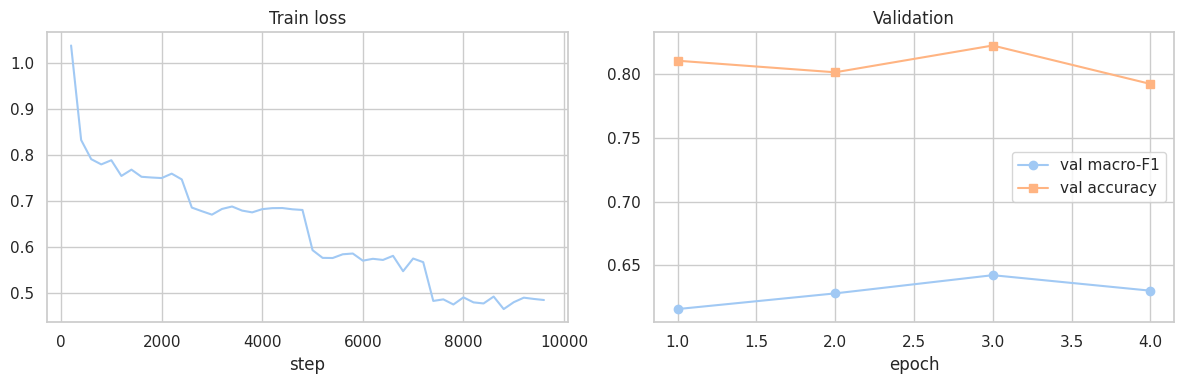


===== BERTurk — VALIDATION (doğal) =====
              precision    recall  f1-score   support

     Olumsuz     0.6064    0.7204    0.6585      1191
        Nötr     0.3082    0.4332    0.3602      2546
      Olumlu     0.9385    0.8789    0.9077     19781

    accuracy                         0.8226     23518
   macro avg     0.6177    0.6775    0.6421     23518
weighted avg     0.8535    0.8226    0.8358     23518

Accuracy: 0.8226 | Macro-F1: 0.6421

===== BERTurk — TEST (doğal) =====
              precision    recall  f1-score   support

     Olumsuz     0.5772    0.6969    0.6314      1191
        Nötr     0.3078    0.4236    0.3566      2547
      Olumlu     0.9377    0.8805    0.9082     19780

    accuracy                         0.8218     23518
   macro avg     0.6076    0.6670    0.6321     23518
weighted avg     0.8512    0.8218    0.8344     23518

Accuracy: 0.8218 | Macro-F1: 0.6321

===== BERTurk — TEST (dengeli) =====
              precision    recall  f1-score   supp

In [13]:
# Eğitim eğrileri
log = pd.DataFrame(trainer.state.log_history)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
if "loss" in log:
    l = log.dropna(subset=["loss"]); ax[0].plot(l["step"], l["loss"]); ax[0].set_title("Train loss"); ax[0].set_xlabel("step")
if "eval_macro_f1" in log:
    e = log.dropna(subset=["eval_macro_f1"])
    ax[1].plot(e["epoch"], e["eval_macro_f1"], "o-", label="val macro-F1")
    ax[1].plot(e["epoch"], e["eval_accuracy"], "s-", label="val accuracy"); ax[1].legend(); ax[1].set_title("Validation"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

def logits_al(ds): return trainer.predict(ds).predictions
L_va, L_te, L_tb = logits_al(val_ds), logits_al(test_ds), logits_al(testb_ds)
P_bert_va, P_bert_te, P_bert_tb = (softmax(L, axis=1) for L in (L_va, L_te, L_tb))

rapor(val_df.label.values,  P_bert_va, "BERTurk — VALIDATION (doğal)")
rapor(test_df.label.values, P_bert_te, "BERTurk — TEST (doğal)")
rapor(test_bal.label.values, P_bert_tb, "BERTurk — TEST (dengeli)")

## 6. Son rötuş: BERT ⊕ TF-IDF harmanı + karar-eşiği (logit bias) ayarı

Doğal dağılımda Olumlu sınıfı baskındır; argmax kararı Nötr/Olumsuz için en iyi macro-F1'i vermeyebilir. Validation üzerinde (a) iki modelin olasılık harman ağırlığı ve (b) sınıf başına bias aranır (yalnızca 3 sayı → aşırı uyum riski düşük). **Test'e hiç dokunulmaz.**

In [14]:
def bias_ara(logp, y, grid=np.arange(-2.0, 2.01, 0.25)):
    """Olumsuz ve Olumlu için bias (Nötr=0 referans) — validation macro-F1'i maksimize eder."""
    en_iyi = (-1, 0.0, 0.0)
    for b0 in grid:
        for b2 in grid:
            p = (logp + np.array([b0, 0.0, b2])).argmax(1)
            f = fast_macro_f1(y, p)
            if f > en_iyi[0]: en_iyi = (f, b0, b2)
    return en_iyi

def harmanla(Pb, Pl, w):
    return w * np.log(Pb + 1e-9) + (1 - w) * np.log(Pl + 1e-9)

yv = val_df.label.values
sonuclar = []
for w in np.arange(0.5, 1.01, 0.1):
    f, b0, b2 = bias_ara(harmanla(P_bert_va, P_lin_va, w), yv)
    sonuclar.append((f, w, b0, b2))
f_arg = fast_macro_f1(yv, P_bert_va.argmax(1))
f_best, W, B0, B2 = max(sonuclar)
print(f"Validation macro-F1 — BERT argmax: {f_arg:.4f} | harman+bias: {f_best:.4f}  (w_bert={W:.1f}, bias={B0:+.2f}/{B2:+.2f})")

BIAS = np.array([B0, 0.0, B2])
def nihai_tahmin(Pb, Pl):
    return (harmanla(Pb, Pl, W) + BIAS).argmax(1)

for ad, y, Pb, Pl in [("TEST (doğal)", test_df.label.values, P_bert_te, P_lin_te),
                      ("TEST (dengeli)", test_bal.label.values, P_bert_tb, P_lin_tb)]:
    p0, p1 = Pb.argmax(1), nihai_tahmin(Pb, Pl)
    print(f"\n{ad}: BERT argmax  acc={accuracy_score(y,p0):.4f} macroF1={f1_score(y,p0,average='macro'):.4f}"
          f"  →  NİHAİ  acc={accuracy_score(y,p1):.4f} macroF1={f1_score(y,p1,average='macro'):.4f}")

Validation macro-F1 — BERT argmax: 0.6421 | harman+bias: 0.6544  (w_bert=0.5, bias=-0.75/+0.50)

TEST (doğal): BERT argmax  acc=0.8218 macroF1=0.6321  →  NİHAİ  acc=0.8507 macroF1=0.6422

TEST (dengeli): BERT argmax  acc=0.6781 macroF1=0.6680  →  NİHAİ  acc=0.6412 macroF1=0.6268


## 7. Nihai değerlendirme ve hata analizi

=== NİHAİ MODEL — TEST (doğal dağılım) ===
              precision    recall  f1-score   support

     Olumsuz     0.6732    0.6037    0.6366      1191
        Nötr     0.3571    0.3698    0.3634      2547
      Olumlu     0.9260    0.9275    0.9268     19780

    accuracy                         0.8507     23518
   macro avg     0.6521    0.6337    0.6422     23518
weighted avg     0.8516    0.8507    0.8510     23518

=== NİHAİ MODEL — TEST (dengeli) ===
              precision    recall  f1-score   support

     Olumsuz     0.8529    0.6037    0.7070      1191
        Nötr     0.5218    0.3812    0.4406      1191
      Olumlu     0.6011    0.9387    0.7329      1191

    accuracy                         0.6412      3573
   macro avg     0.6586    0.6412    0.6268      3573
weighted avg     0.6586    0.6412    0.6268      3573



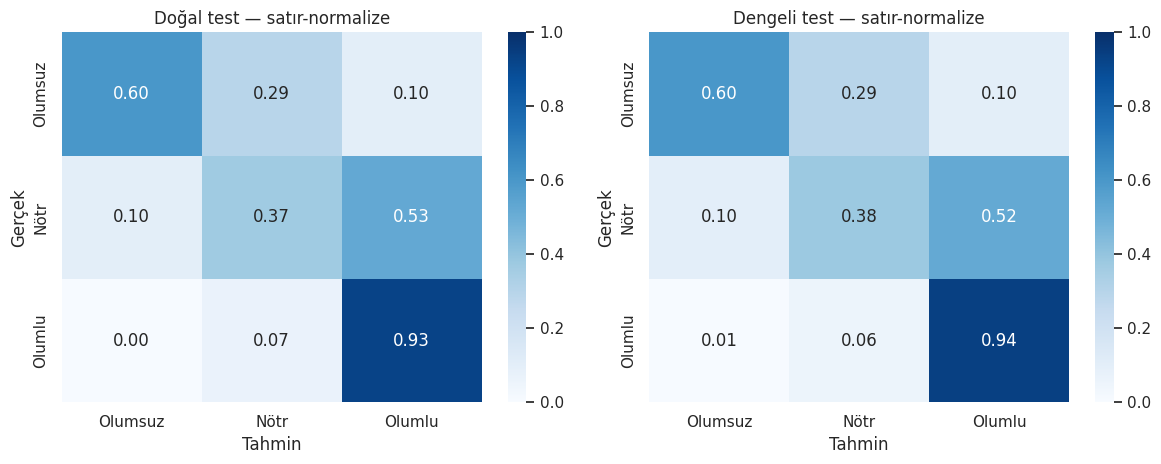


Yıldıza göre doğruluk (doğal test):
          mean  count
rating               
1       0.7626    615
2       0.4340    576
3       0.3698   2547
4       0.8358   5469
5       0.9625  14311

En emin 12 yanlış tahmin:


,review,rating,sentiment,tahmin,guven
8904,Ürün çok iyi. Özellike çekiş gücü ve temizliği...,3,Nötr,Olumlu,0.984486
23130,Tam bir fiyat performans canavarı. Kesinlikle ...,3,Nötr,Olumlu,0.981666
6445,ürünü İnternet'e 2 si çıktığından beri takip e...,3,Nötr,Olumlu,0.980775
19744,"Mis gibi çilek kokusu, ağızda bıraktığı tat, t...",3,Nötr,Olumlu,0.978397
17350,çok kullanışlı bir ürün doğumdan hemen sonra 2...,3,Nötr,Olumlu,0.977774
16007,"Görüntü kalitesi, duruşu boyutu mükemmel. sony...",2,Olumsuz,Olumlu,0.977305
14764,"Hızlı teslimat, güvendiğimiz hizmet. Üstelik f...",3,Nötr,Olumlu,0.974525
8154,Harika ürün. Ve hızlı teslimat teşekkürler,3,Nötr,Olumlu,0.972127
6449,Mükemmel ve kullanışlı..Ayrıcada sağlam..Kargo...,3,Nötr,Olumlu,0.967852
5683,Geldiğinden beri günde 2 defa kullanıyorum. Ha...,3,Nötr,Olumlu,0.967372


In [15]:
y_te = test_df.label.values
p_te = nihai_tahmin(P_bert_te, P_lin_te)
y_tb = test_bal.label.values
p_tb = nihai_tahmin(P_bert_tb, P_lin_tb)

print("=== NİHAİ MODEL — TEST (doğal dağılım) ===")
print(classification_report(y_te, p_te, target_names=SINIFLAR, digits=4))
print("=== NİHAİ MODEL — TEST (dengeli) ===")
print(classification_report(y_tb, p_tb, target_names=SINIFLAR, digits=4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
for a, (y, p, t) in zip(ax, [(y_te, p_te, "Doğal test"), (y_tb, p_tb, "Dengeli test")]):
    cm = confusion_matrix(y, p, normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=SINIFLAR, yticklabels=SINIFLAR, ax=a, vmin=0, vmax=1)
    a.set_title(f"{t} — satır-normalize"); a.set_xlabel("Tahmin"); a.set_ylabel("Gerçek")
plt.tight_layout(); plt.show()

# Hangi yıldız puanında hata yoğun? (4 ve 3 yıldız sınır bölgesi)
hata = test_df.assign(tahmin=[SINIFLAR[i] for i in p_te], dogru=(p_te == y_te))
print("\nYıldıza göre doğruluk (doğal test):")
print(hata.groupby("rating")["dogru"].agg(["mean", "count"]).round(4))

# En emin yanlış tahminler → etiket gürültüsü mü, model hatası mı?
P_son = softmax(harmanla(P_bert_te, P_lin_te, W) + BIAS, axis=1)
hata["guven"] = P_son.max(1)
print("\nEn emin 12 yanlış tahmin:")
display(hata[~hata.dogru].sort_values("guven", ascending=False)
        [["review", "rating", "sentiment", "tahmin", "guven"]].head(12))

## 8. Kaydetme ve yeni yorumlar üzerinde tahmin

In [16]:
KAYIT = "berturk_hepsiburada_final"
trainer.save_model(KAYIT); tok.save_pretrained(KAYIT)
import joblib
joblib.dump({"kelime_vec": kelime_vec, "karakter_vec": karakter_vec, "lin": lin}, f"{KAYIT}/tfidf_lin.joblib")
json.dump({"siniflar": SINIFLAR, "w_bert": float(W), "bias": BIAS.tolist(), "max_len": MAX_LEN},
          open(f"{KAYIT}/karar_ayarlari.json", "w"), ensure_ascii=False, indent=2)
print("Kaydedildi →", KAYIT)

def duygu_tahmin(yorumlar):
    """Liste halinde yorum alır; (etiket, olasılıklar) döner. Kayıtlı harman + bias ayarlarını kullanır."""
    ham = [hafif_norm(y) for y in yorumlar]
    model.eval()
    giris = tok(ham, truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt").to(model.device)
    with torch.no_grad():
        Pb = softmax(model(**giris).logits.float().cpu().numpy(), axis=1)
    X = hstack([kelime_vec.transform([tr_lower(t) for t in ham]),
                karakter_vec.transform([tr_lower(t) for t in ham])]).tocsr()
    Pl = lin.predict_proba(X)
    P = softmax(harmanla(Pb, Pl, W) + BIAS, axis=1)
    return [SINIFLAR[i] for i in P.argmax(1)], P

ornekler = [
    "Ürün gayet iyi ama kargo çok geç geldi",
    "Berbat, hiç tavsiye etmem, param boşa gitti",
    "Fiyat performans ürünü, çok memnun kaldım",
    "Ne iyi ne kötü, idare eder",
    "guzel urun tavsiye ederim",
    "İADE ETTİM!!! Kutusu ezik geldi",
]
etiket, olas = duygu_tahmin(ornekler)
for t, e, p in zip(ornekler, etiket, olas):
    print(f"{e:8s} {np.round(p,2)}  | {t}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Kaydedildi → berturk_hepsiburada_final
Nötr     [0.01 0.53 0.46]  | Ürün gayet iyi ama kargo çok geç geldi
Olumsuz  [0.91 0.05 0.03]  | Berbat, hiç tavsiye etmem, param boşa gitti
Olumlu   [0.   0.02 0.97]  | Fiyat performans ürünü, çok memnun kaldım
Nötr     [0.04 0.94 0.02]  | Ne iyi ne kötü, idare eder
Olumlu   [0.   0.27 0.73]  | guzel urun tavsiye ederim
Olumsuz  [0.84 0.12 0.04]  | İADE ETTİM!!! Kutusu ezik geldi
